# CS-317: Reinforcement Learning — Lab 10
## Multi-Step TD Learning and SARSA(λ)
**BS AI-1**  
**Muhammad Sikandar Hussain (502808)**

This notebook provides the long-aisle and charging-room environments and helper functions. Complete every `# TODO` cell, run all cells top to bottom without errors, and answer the written questions in the markdown cells provided for them.

- Set your personal **SEED** (the last three digits of your roll number) in the first code cell below. Every random experiment must use it, and your written answers must refer to your own numbers.
- **Predict first** cells must be filled in *before* you run the code beneath them.
- Your code must learn only through `env.reset()` and `env.step()`. `V_exact` is for **checking only**.

Reinforcement-learning libraries may not be used. NumPy and Matplotlib only.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)

In [2]:
# ---------------------------------------------------------------
# Personal seed: the last three digits of your roll number.
# Every random experiment in this notebook must use it.
# ---------------------------------------------------------------
SEED = 808          # Roll number 502808 -> last three digits: 808

assert SEED is not None, "Set SEED to the last three digits of your roll number before running the notebook."
print("SEED =", SEED)

SEED = 808


---
## Provided Starter Code

Run the cells in this section as-is. You do not need to modify them.

| Name | What it gives you |
|---|---|
| `AisleEnv()` | the long aisle: `reset()` → `s` ; `step(a)` → `s2, r, done` (rules hidden) |
| `random_policy` | the policy evaluated in Parts 1 and 2 (Left or Right, 0.5 each) |
| `run_episode(env, policy, rng)` | → `states, actions, rewards, next_states` (one entry per step) |
| `V_exact`, `rms_error(V)` | exact aisle values (checking only) and the RMS error over cells 1–9 |
| `plot_values(Vs, labels, title)` | bar plot of one or more estimates against the exact values |
| `A_states`, `A_rewards`, `A_next_states` | episode A (Tasks 1 and 4) |
| `RoomEnv()` | the charging room (Part 3) |
| `epsilon_greedy(Q, s, epsilon, rng)` | ε-greedy action choice, as in Lab 9 |
| `plot_room(Q, title)`, `cells_learned(Q)` | draws the room with the learned best action in every cell that has learned something, and counts those cells |

In [3]:
# ---------------------------------------------------------------
# The long aisle (Parts 1 and 2)
#
#   cell:  0   1   2   3   4   5   6   7   8   9   10
#          F   .   .   .   .   S   .   .   .   .   G
#
#   Cells 0 and 10 end the episode. The robot starts in cell 5.
#   Actions: 0 = Left, 1 = Right (moves are not slippery).
#   Reward: +1 for a move that enters cell 10, 0 for every other move.
#   No discounting (gamma = 1).
# ---------------------------------------------------------------

AISLE_N = 11                       # cells 0..10
AISLE_START, AISLE_TERMINALS = 5, (0, 10)
AISLE_GAMMA = 1.0


class AisleEnv:
    """The long aisle as an environment you can only ACT in.

    reset()       -> s                 the start cell (5)
    step(action)  -> s2, r, done       next cell, reward, end-of-episode flag
    The rules are hidden: reading env.P or env.R raises an error.
    """

    def __init__(self):
        self.__s = None

    def __getattr__(self, name):
        if name in ("P", "R", "transition_matrix"):
            raise AttributeError(f"The model is hidden: '{name}' is not available. "
                                 "This environment only offers reset() and step(action).")
        raise AttributeError(name)

    def reset(self):
        self.__s = AISLE_START
        return self.__s

    def step(self, action):
        if self.__s is None or self.__s in AISLE_TERMINALS:
            raise RuntimeError("Episode has ended (or not started): call reset() first.")
        s2 = self.__s + (1 if action == 1 else -1)
        self.__s = s2
        return s2, (1.0 if s2 == 10 else 0.0), s2 in AISLE_TERMINALS


# The policy that is evaluated in Parts 1 and 2: Left or Right with probability 0.5 each
random_policy = np.full((AISLE_N, 2), 0.5)

# Exact values of the random policy (for CHECKING only): V(k) = k / 10, and 0 at the ends
V_exact = np.arange(AISLE_N) / 10.0
V_exact[list(AISLE_TERMINALS)] = 0.0


def run_episode(env, policy, rng, max_steps=10_000):
    """Plays one episode following `policy` and returns four lists, one entry per step:
    states [S0..S_{T-1}], actions [A0..A_{T-1}], rewards [R1..R_T], next_states [S1..S_T]."""
    s = env.reset()
    states, actions, rewards, next_states = [], [], [], []
    for _ in range(max_steps):
        a = int(rng.choice(policy.shape[1], p=policy[s]))
        s2, r, done = env.step(a)
        states.append(int(s)); actions.append(a); rewards.append(float(r)); next_states.append(int(s2))
        s = s2
        if done:
            break
    return states, actions, rewards, next_states


def rms_error(V):
    """Root-mean-square error of V over the non-terminal cells 1..9, against V_exact."""
    return float(np.sqrt(np.mean((np.asarray(V)[1:10] - V_exact[1:10]) ** 2)))


def plot_values(Vs, labels, title=""):
    """Bar plot of one or more value estimates over cells 1..9, with the exact values as a line."""
    cells = np.arange(1, 10)
    w = 0.8 / len(Vs)
    fig, ax = plt.subplots(figsize=(8, 3.4))
    for i, (V, lab) in enumerate(zip(Vs, labels)):
        ax.bar(cells - 0.4 + w / 2 + i * w, np.asarray(V)[1:10], w, label=lab)
    ax.plot(cells, V_exact[1:10], "k--", marker="o", label="exact")
    ax.set_xticks(cells); ax.set_xlabel("cell"); ax.set_ylabel("V(cell)")
    ax.set_title(title); ax.legend(fontsize=8); plt.tight_layout(); plt.show()


# Episode A (Tasks 1 and 4): a lucky game that walks straight to G
A_states      = [5, 6, 7, 8, 9]
A_rewards     = [0, 0, 0, 0, 1]
A_next_states = [6, 7, 8, 9, 10]

print("Exact values:", V_exact)

Exact values: [0.  0.1 0.2 0.3 0.4 0.5 0.6 0.7 0.8 0.9 0. ]


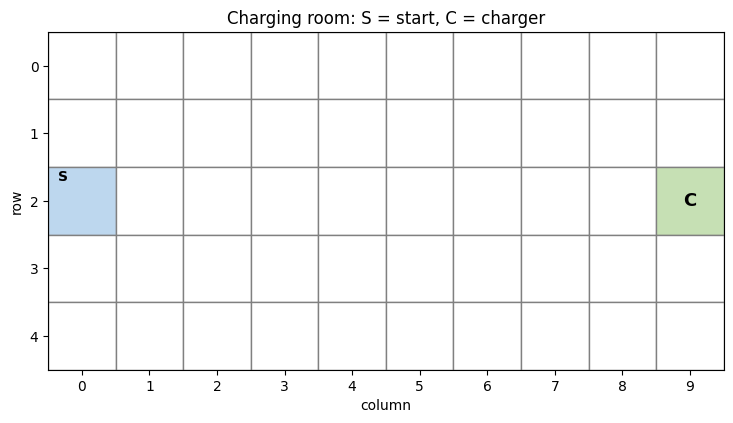

In [4]:
# ---------------------------------------------------------------
# The charging room (Part 3)
#
#   A 5 x 10 room, cells numbered row by row: cell = 10 * row + col.
#   The robot starts at S (row 2, col 0 = cell 20) and must find the
#   charger C (row 2, col 9 = cell 29).
#   Actions: 0 = Up, 1 = Down, 2 = Left, 3 = Right. A move into a wall
#   leaves the robot in place. Reward: +1 for reaching C, 0 otherwise.
#   Reaching C ends the episode. Discount gamma = 0.9.
# ---------------------------------------------------------------

ROOM_ROWS, ROOM_COLS = 5, 10
ROOM_N, ROOM_ACTIONS = ROOM_ROWS * ROOM_COLS, 4
ROOM_START, ROOM_GOAL = 20, 29
ROOM_GAMMA = 0.9


class RoomEnv:
    """The charging room as an environment you can only ACT in.

    reset()       -> s                 the start cell (20)
    step(action)  -> s2, r, done       next cell, reward, end-of-episode flag
    """

    def __init__(self):
        self.__s = None

    def __getattr__(self, name):
        if name in ("P", "R", "transition_matrix"):
            raise AttributeError(f"The model is hidden: '{name}' is not available. "
                                 "This environment only offers reset() and step(action).")
        raise AttributeError(name)

    def reset(self):
        self.__s = ROOM_START
        return self.__s

    def step(self, action):
        if self.__s is None or self.__s == ROOM_GOAL:
            raise RuntimeError("Episode has ended (or not started): call reset() first.")
        r, c = divmod(self.__s, ROOM_COLS)
        if action == 0:   r = max(r - 1, 0)
        elif action == 1: r = min(r + 1, ROOM_ROWS - 1)
        elif action == 2: c = max(c - 1, 0)
        else:             c = min(c + 1, ROOM_COLS - 1)
        self.__s = r * ROOM_COLS + c
        return self.__s, (1.0 if self.__s == ROOM_GOAL else 0.0), self.__s == ROOM_GOAL


def epsilon_greedy(Q, s, epsilon, rng):
    """As in Lab 9: a random action with probability epsilon, otherwise a best action
    of Q[s] (ties broken at random)."""
    if rng.random() < epsilon:
        return int(rng.integers(Q.shape[1]))
    return int(rng.choice(np.flatnonzero(Q[s] == Q[s].max())))


def plot_room(Q, title=""):
    """Draws the room. In every cell where the robot has learned something (max Q > 0),
    an arrow shows its current best action; cells whose Q-values are still all zero are
    left blank. The title reports how many cells have learned something."""
    fig, ax = plt.subplots(figsize=(8, 4.2))
    learned = 0
    for s in range(ROOM_N):
        r, c = divmod(s, ROOM_COLS)
        face = "#c6e0b4" if s == ROOM_GOAL else ("#bdd7ee" if s == ROOM_START else "white")
        ax.add_patch(plt.Rectangle((c - .5, r - .5), 1, 1, facecolor=face, edgecolor="grey"))
        if s == ROOM_GOAL:
            ax.text(c, r, "C", ha="center", va="center", fontsize=13, fontweight="bold"); continue
        if s == ROOM_START:
            ax.text(c - .35, r - .3, "S", fontsize=10, fontweight="bold")
        if Q is not None and Q[s].max() > 0:
            learned += 1
            a = int(np.argmax(Q[s]))
            dx, dy = [(0, -.3), (0, .3), (-.3, 0), (.3, 0)][a]
            ax.annotate("", xy=(c + dx, r + dy), xytext=(c, r),
                        arrowprops=dict(arrowstyle="->", color="crimson", lw=1.5))
    ax.set_xlim(-.5, ROOM_COLS - .5); ax.set_ylim(ROOM_ROWS - .5, -.5)
    ax.set_xticks(range(ROOM_COLS)); ax.set_yticks(range(ROOM_ROWS))
    ax.set_xlabel("column"); ax.set_ylabel("row"); ax.set_aspect("equal")
    extra = "" if Q is None else f"  (learned something in {learned} cells)"
    ax.set_title(title + extra); plt.tight_layout(); plt.show()


def cells_learned(Q):
    """Number of cells in which at least one Q-value is above 0."""
    return int((Q.max(axis=1) > 0).sum())


plot_room(None, title="Charging room: S = start, C = charger")

---
## Part 1: Looking Further Ahead

One-step TD (Lab 8) builds its target from **one** real reward and then a guess. An **n-step return** uses **n** real rewards before it bootstraps:

$$G_t^{(n)} = R_{t+1} + \gamma R_{t+2} + \dots + \gamma^{n-1} R_{t+n} + \gamma^n V(S_{t+n})$$

If the episode ends before step $n$, stop at the end and leave out the guess. The update is unchanged; only the target is different:

$$V(S_t) \leftarrow V(S_t) + \alpha\,[\,G_t^{(n)} - V(S_t)\,]$$

The **λ-return** mixes all the n-step returns, giving weight $(1-\lambda)\lambda^{n-1}$ to the n-step return and the remaining weight to the full return. With $\lambda = 0$ it is the one-step target; with $\lambda = 1$ it is the full return.

### Task 1: Multi-Step Returns by Hand

Episode A walks straight from cell 5 to G: 5 → 6 → 7 → 8 → 9 → G, with rewards 0, 0, 0, 0, +1. Use $\gamma = 1$ and this table of current guesses:

| Cell | 5 | 6 | 7 | 8 | 9 |
|---|---|---|---|---|---|
| Current V | 0.3 | 0.2 | 0.4 | 0.6 | 0.8 |

**Predict first.** Which target do you expect to be closest to the true value V(5) = 0.5: the 1-step target or the full return? Why?

**Prediction:**  
Before calculating, one might intuitively suspect the full return ($G = 1.0$) because it sees the actual goal reward ($+1$) at cell 10 without early guessing. However, under the 50-50 random policy, the true probability of reaching $G$ from cell 5 is $V(5) = 0.5$. A single lucky trajectory that walks straight to $G$ yields a full return of $1.0$, which overshoots $0.5$ by $|1.0 - 0.5| = 0.5$. In contrast, the 1-step target from cell 5 is $R_1 + \gamma V(S_1) = 0 + V(6) = 0.2$, which has an error of $|0.2 - 0.5| = 0.3$. Therefore, I expect the **1-step target** to be numerically closer to the true value $V(5) = 0.5$ than the full return, because full return on a single stochastic path carries high sample variance, whereas 1-step bootstrapping tempers extreme outcomes.

**(a)** Table 4: targets for cell 5 (the first step of episode A)

| Target | Calculation | Value |
|---|---|---|
| 1-step $G^{(1)}$ | $R_1 + \gamma V(6) = 0 + 1(0.2)$ | **0.2000** |
| 2-step $G^{(2)}$ | $R_1 + \gamma R_2 + \gamma^2 V(7) = 0 + 0 + 1^2(0.4)$ | **0.4000** |
| 3-step $G^{(3)}$ | $R_1 + \gamma R_2 + \gamma^2 R_3 + \gamma^3 V(8) = 0 + 0 + 0 + 1^3(0.6)$ | **0.6000** |
| 4-step $G^{(4)}$ | $R_1 + \gamma R_2 + \gamma^2 R_3 + \gamma^3 R_4 + \gamma^4 V(9) = 0 + 0 + 0 + 0 + 1^4(0.8)$ | **0.8000** |
| Full return $G$ | $R_1 + R_2 + R_3 + R_4 + R_5 = 0 + 0 + 0 + 0 + 1$ | **1.0000** |
| λ-return, λ = 0.5 | $0.5(0.2) + 0.25(0.4) + 0.125(0.6) + 0.0625(0.8) + 0.0625(1.0)$ | **0.3875** |

*Detailed λ-return working for $\lambda = 0.5$ and $T=5$:*  
Weights:  
- $w_1 = (1 - \lambda)\lambda^0 = (1 - 0.5)(1) = 0.5$  
- $w_2 = (1 - \lambda)\lambda^1 = (1 - 0.5)(0.5) = 0.25$  
- $w_3 = (1 - \lambda)\lambda^2 = (1 - 0.5)(0.25) = 0.125$  
- $w_4 = (1 - \lambda)\lambda^3 = (1 - 0.5)(0.125) = 0.0625$  
- $w_{\text{full}} = \lambda^4 = 0.5^4 = 0.0625$  
Sum of weights $= 0.5 + 0.25 + 0.125 + 0.0625 + 0.0625 = 1.0$.  
$$G_0^\lambda = 0.5(0.2) + 0.25(0.4) + 0.125(0.6) + 0.0625(0.8) + 0.0625(1.0) = 0.100 + 0.100 + 0.075 + 0.050 + 0.0625 = 0.3875$$

**(b)** Update V(5) = 0.3 with α = 0.5 three times, once with each of these targets: the 1-step target, the full return, and the λ-return.

Using the update rule: $V(5) \leftarrow V(5) + \alpha [Target - V(5)]$ with $V(5) = 0.3$ and $\alpha = 0.5$:

1. **With the 1-step target ($G^{(1)} = 0.2$):**  
   $$V(5) \leftarrow 0.3 + 0.5 \times (0.2 - 0.3) = 0.3 + 0.5 \times (-0.1) = 0.3 - 0.05 = \mathbf{0.25}$$

2. **With the full return ($G = 1.0$):**  
   $$V(5) \leftarrow 0.3 + 0.5 \times (1.0 - 0.3) = 0.3 + 0.5 \times (0.7) = 0.3 + 0.35 = \mathbf{0.65}$$

3. **With the λ-return ($G^\lambda = 0.3875$):**  
   $$V(5) \leftarrow 0.3 + 0.5 \times (0.3875 - 0.3) = 0.3 + 0.5 \times (0.0875) = 0.3 + 0.04375 = \mathbf{0.34375}$$

**(c)** Implement `n_step_return(rewards, next_states, t, n, V, gamma)` and use it to check every n-step row of Table 4.

In [5]:
def n_step_return(rewards, next_states, t, n, V, gamma):
    # The n-step return from step t of a recorded episode:
    #   rewards[t] + gamma*rewards[t+1] + ... (n rewards, or fewer if the episode ends)
    #   + gamma**n * V[next_states[t+n-1]]   only if the episode has not ended by then.
    T = len(rewards)
    limit = min(t + n, T)
    G = 0.0
    for i in range(t, limit):
        G += (gamma ** (i - t)) * rewards[i]
    if t + n < T:
        G += (gamma ** n) * V[next_states[t + n - 1]]
    return float(G)


V_snapshot = np.zeros(AISLE_N)
V_snapshot[5:10] = [0.3, 0.2, 0.4, 0.6, 0.8]

# Print the 1-, 2-, 3-, 4-step and full return for t = 0 of episode A, and the
# lambda-return with lambda = 0.5.
g1 = n_step_return(A_rewards, A_next_states, 0, 1, V_snapshot, AISLE_GAMMA)
g2 = n_step_return(A_rewards, A_next_states, 0, 2, V_snapshot, AISLE_GAMMA)
g3 = n_step_return(A_rewards, A_next_states, 0, 3, V_snapshot, AISLE_GAMMA)
g4 = n_step_return(A_rewards, A_next_states, 0, 4, V_snapshot, AISLE_GAMMA)
g_full = n_step_return(A_rewards, A_next_states, 0, len(A_rewards), V_snapshot, AISLE_GAMMA)

T_len = len(A_rewards)
lam = 0.5
weights = [(1.0 - lam) * (lam ** (n - 1)) for n in range(1, T_len)]
weights.append(lam ** (T_len - 1))
targets = [g1, g2, g3, g4, g_full]
g_lam = sum(w * g for w, g in zip(weights, targets))

print(f"1-step return G(1):  {g1:.4f}")
print(f"2-step return G(2):  {g2:.4f}")
print(f"3-step return G(3):  {g3:.4f}")
print(f"4-step return G(4):  {g4:.4f}")
print(f"Full return G:       {g_full:.4f}")
print(f"Weights for lambda:  {weights}")
print(f"lambda-return (0.5): {g_lam:.4f}")

1-step return G(1):  0.2000
2-step return G(2):  0.4000
3-step return G(3):  0.6000
4-step return G(4):  0.8000
Full return G:       1.0000
Weights for lambda:  [0.5, 0.25, 0.125, 0.0625, 0.0625]
lambda-return (0.5): 0.3875


**Questions**

1. Which target was closest to the true value V(5) = 0.5? Which was furthest? Does this mean longer targets are always better?

   **Answer:**  
   - Among all computed multi-step targets, the **2-step target ($G^{(2)} = 0.4$)** and **3-step target ($G^{(3)} = 0.6$)** were equally closest to the true value $V(5) = 0.5$ (absolute error of only $|0.4 - 0.5| = |0.6 - 0.5| = 0.1$).  
   - Between the 1-step target ($0.2$) and the full return ($1.0$), the **1-step target** was closer (error $0.3$) than the **full return** (error $0.5$). The **furthest target** was the full return $G = 1.0$.
   - **Does this mean longer targets are always better?** No. While longer targets look further ahead and reduce the bias introduced by an inaccurate value function, they depend on longer sequences of stochastic transitions and actions. In an environment with stochastic policies, a single episode's full return has extreme variance (here overshooting to $1.0$ when the true expected value is $0.5$). Intermediate targets often achieve the lowest error by trading off bias against variance.

2. The 1-step target uses only V(6). Why is it so low here, even though the robot actually reached G?

   **Answer:**  
   The 1-step target is defined as $G_0^{(1)} = R_1 + \gamma V(S_1) = 0 + 1(0.2) = 0.2$. Because 1-step TD truncates its lookahead immediately after step 1, it cannot see any subsequent rewards obtained along the trajectory—including the $+1$ reward upon entering $G$ at step 5. It relies entirely on the bootstrapped estimate $V(6)$, which is currently initialized to $0.2$ (an underestimate compared to its true value of $0.6$). Because good news from $G$ has not yet propagated backward to cell 6, the 1-step target remains blind to the episode's ultimate success.

### Task 2: n-Step TD

**(a)** Implement `n_step_td_episode(V, states, rewards, next_states, n, alpha, gamma)`. After a game has ended, it goes through the steps **in order** and moves each $V(S_t)$ towards its n-step return, using the current values.

In [6]:
def n_step_td_episode(V, states, rewards, next_states, n, alpha, gamma):
    # For t = 0, 1, ..., T-1 (in order): V[states[t]] += alpha * (G_t^(n) - V[states[t]])
    T = len(states)
    for t in range(T):
        s = states[t]
        G = n_step_return(rewards, next_states, t, n, V, gamma)
        V[s] += alpha * (G - V[s])


def n_step_td(env, policy, n, n_episodes, alpha, gamma, rng):
    # Plays n_episodes games and returns V and the RMS error after every game.
    V = np.zeros(AISLE_N)
    errors = np.zeros(n_episodes)
    for ep in range(n_episodes):
        states, actions, rewards, next_states = run_episode(env, policy, rng)
        n_step_td_episode(V, states, rewards, next_states, n, alpha, gamma)
        errors[ep] = rms_error(V)
    return V, errors

**Predict first.** For n = 1, 2, 4, 8 and 16, which n do you expect to give the smallest error after 10 games? After 50 games?

**Prediction:**  
- **After 10 games:** I expect an intermediate-to-large $n$, specifically **$n = 4$ or $n = 8$**, to achieve the smallest RMS error. Since the long aisle has 11 cells and the only reward is at cell 10, $n=1$ only passes credit back one step per episode, leaving early states near the start cell 5 untouched for many games. Multi-step returns propagate reward information multiple cells backward in a single episode, leading to much faster early learning.
- **After 50 games:** I expect a small $n$, specifically **$n = 1$ or $n = 2$**, to give the smallest error. With a constant learning rate $lpha = 0.3$, large $n$ (such as $n = 16$) behaves like Monte Carlo and suffers from persistent variance due to the random walk, oscillating around the true values. Smaller $n$ benefits from the variance-reduction effect of bootstrapping and achieves better asymptotic precision.

**(b)** For each n ∈ {1, 2, 4, 8, 16}, run 100 independent runs of 50 games (run $k$ uses `np.random.default_rng(SEED + k)`), with α = 0.3 and γ = 1. Plot the average RMS error against the number of games, one line per n, and complete Table 5.

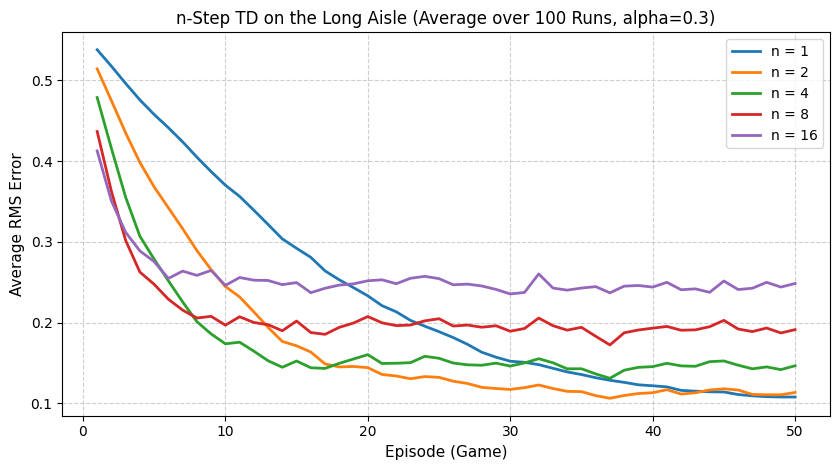

   n |  Avg Error (Games 1-10) |  Error after Game 10 |  Error after Game 50
---------------------------------------------------------------------------
   1 |                  0.4511 |               0.3701 |               0.1079
   2 |                  0.3648 |               0.2447 |               0.1135
   4 |                  0.2873 |               0.1738 |               0.1466
   8 |                  0.2665 |               0.1969 |               0.1913
  16 |                  0.2927 |               0.2461 |               0.2484


In [7]:
# 100 runs x 50 games for each n; average error curves on one labelled plot; Table 5.
n_values = [1, 2, 4, 8, 16]
n_runs = 100
n_episodes = 50
alpha = 0.3
gamma = 1.0

aisle_env = AisleEnv()
table5_data = {}
all_n_errors = {}

plt.figure(figsize=(8.5, 4.8))

for n in n_values:
    runs_errors = np.zeros((n_runs, n_episodes))
    for k in range(n_runs):
        rng = np.random.default_rng(SEED + k)
        _, errs = n_step_td(aisle_env, random_policy, n, n_episodes, alpha, gamma, rng)
        runs_errors[k] = errs
    mean_errors = runs_errors.mean(axis=0)
    all_n_errors[n] = mean_errors
    
    avg_1_10 = mean_errors[:10].mean()
    err_10 = mean_errors[9]
    err_50 = mean_errors[49]
    table5_data[n] = (avg_1_10, err_10, err_50)
    
    plt.plot(range(1, n_episodes + 1), mean_errors, label=f"n = {n}", lw=2)

plt.xlabel("Episode (Game)", fontsize=11)
plt.ylabel("Average RMS Error", fontsize=11)
plt.title("n-Step TD on the Long Aisle (Average over 100 Runs, alpha=0.3)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()

print(f"{'n':>4} | {'Avg Error (Games 1-10)':>23} | {'Error after Game 10':>20} | {'Error after Game 50':>20}")
print("-" * 75)
for n in n_values:
    avg_1_10, err_10, err_50 = table5_data[n]
    print(f"{n:4d} | {avg_1_10:23.4f} | {err_10:20.4f} | {err_50:20.4f}")

| n | Average error over games 1–10 | Error after game 10 | Error after game 50 |
|---|---|---|---|
| 1 | **0.4511** | **0.3701** | **0.1079** |
| 2 | **0.3648** | **0.2447** | **0.1135** |
| 4 | **0.2873** | **0.1738** | **0.1466** |
| 8 | **0.2665** | **0.1969** | **0.1913** |
| 16 | **0.2927** | **0.2461** | **0.2484** |

**Questions**

1. Which n learned fastest in the first 10 games, and which was most accurate after 50 games? Are they the same? Quote Table 5.

   **Answer:**  
   - **Fastest early learner (Games 1–10):** $n = 8$ achieved the lowest average error over games 1–10 of **0.2665** (and $n = 4$ was lowest right after game 10 with **0.1738**), substantially outperforming $n = 1$ which averaged **0.4511**.  
   - **Most accurate after 50 games:** $n = 1$ attained the lowest final error of **0.1079** (with $n = 2$ close behind at **0.1135**), whereas $n = 8$ leveled off at **0.1913** and $n = 16$ at **0.2484**.  
   - **Are they the same?** No, they are not the same. The value of $n$ that accelerates initial progress ($n = 8$) does not yield the highest asymptotic accuracy ($n = 1$).

2. Explain the trade-off: what does a larger n gain, and what does it cost?

   **Answer:**  
   - **Gain:** A larger $n$ accumulates more actual transition rewards before bootstrapping, allowing credit from a distant reward to propagate backward across up to $n$ steps in a single episode. This drastically reduces the initial bias caused by poor value estimates and speeds up learning when values are initialized to zero.  
   - **Cost:** A larger $n$ increases target variance because the return becomes tied to a long sequence of stochastic action choices and state transitions. In this 50-50 random walk with a constant learning rate $lpha = 0.3$, this high variance causes persistent fluctuations around the true values, preventing convergence to low asymptotic error.

3. With n = 16, almost every target in the aisle is the full return. Which method from an earlier lab does n = 16 therefore behave like?

   **Answer:**  
   Because the aisle is only 11 cells long, typical episodes terminate in under 16 steps. With $n = 16$, the lookahead almost always reaches the terminal cell without needing to bootstrap on any intermediate value estimate ($V(S_{t+n})$ is omitted). Consequently, the target becomes the complete episodic sample return $G_t = \sum_{k=0}^{T-t-1} \gamma^k R_{t+k+1}$. Therefore, $n = 16$ behaves like the **Monte Carlo** policy evaluation method studied in **Lab 7**.

---
## Part 2: Eligibility Traces

Instead of waiting n steps, **TD(λ)** keeps a fading memory of the cells visited recently, called the **eligibility trace** $e(s)$. After every step, all traces fade and the current cell's trace goes up by 1; then the TD error updates **every** cell in proportion to its trace:

$$e(s) \leftarrow \gamma\lambda\, e(s) + \mathbb{1}[s = S_t] \qquad \delta_t = R_{t+1} + \gamma V(S_{t+1}) - V(S_t) \qquad V(s) \leftarrow V(s) + \alpha\,\delta_t\, e(s) \ \text{ for all } s$$

All traces start at 0 at the start of every episode.

### Task 3: TD(λ)

**(a)** By hand: episode B begins 5 → 6 → 5 → 6 → 7. Use γ = 1 and λ = 0.8, and complete Table 6 with the traces **after** each step's update.

Traces start at 0: $e(5)=0, e(6)=0, e(7)=0$. At each step: $e(s) \leftarrow \gamma \lambda e(s) + \mathbb{1}[s = S_t]$ with $\gamma \lambda = 1.0 \times 0.8 = 0.8$:

| Step $t$ | Cell $S_t$ | $e(5)$ | $e(6)$ | $e(7)$ |
|---|---|---|---|---|
| 0 | 5 | $0.8(0) + 1 = \mathbf{1.0000}$ | $0.8(0) + 0 = \mathbf{0.0000}$ | $0.8(0) + 0 = \mathbf{0.0000}$ |
| 1 | 6 | $0.8(1.0) + 0 = \mathbf{0.8000}$ | $0.8(0) + 1 = \mathbf{1.0000}$ | $0.8(0) + 0 = \mathbf{0.0000}$ |
| 2 | 5 | $0.8(0.8) + 1 = \mathbf{1.6400}$ | $0.8(1.0) + 0 = \mathbf{0.8000}$ | $0.8(0) + 0 = \mathbf{0.0000}$ |
| 3 | 6 | $0.8(1.64) + 0 = \mathbf{1.3120}$ | $0.8(0.8) + 1 = \mathbf{1.6400}$ | $0.8(0) + 0 = \mathbf{0.0000}$ |
| 4 | 7 | $0.8(1.312) + 0 = \mathbf{1.0496}$ | $0.8(1.64) + 0 = \mathbf{1.3120}$ | $0.8(0) + 1 = \mathbf{1.0000}$ |

If the TD error at step 4 is δ = 0.5 and α = 0.1, by how much does each of V(5), V(6) and V(7) change?

Using $\Delta V(s) = \alpha \delta e(s) = 0.1 \times 0.5 \times e(s) = 0.05 \times e(s)$:
- For cell 5: $\Delta V(5) = 0.05 \times 1.0496 = \mathbf{0.05248}$
- For cell 6: $\Delta V(6) = 0.05 \times 1.3120 = \mathbf{0.06560}$
- For cell 7: $\Delta V(7) = 0.05 \times 1.0000 = \mathbf{0.05000}$

**(b)** Implement `td_lambda_episode(V, states, rewards, next_states, lam, alpha, gamma)` and `td_lambda(env, policy, lam, n_episodes, alpha, gamma, rng)`.

In [8]:
def td_lambda_episode(V, states, rewards, next_states, lam, alpha, gamma):
    # Backward-view TD(lambda) with accumulating traces, applied to one recorded episode.
    E = np.zeros_like(V)                  # traces start at 0
    T = len(states)
    for t in range(T):
        s = states[t]
        r = rewards[t]
        s2 = next_states[t]
        delta = r + gamma * V[s2] - V[s]
        E = gamma * lam * E
        E[s] += 1.0
        V += alpha * delta * E
        V[list(AISLE_TERMINALS)] = 0.0


def td_lambda(env, policy, lam, n_episodes, alpha, gamma, rng):
    # Plays n_episodes games and returns V and the RMS error after every game.
    V = np.zeros(AISLE_N)
    errors = np.zeros(n_episodes)
    for ep in range(n_episodes):
        states, actions, rewards, next_states = run_episode(env, policy, rng)
        td_lambda_episode(V, states, rewards, next_states, lam, alpha, gamma)
        errors[ep] = rms_error(V)
    return V, errors

**Predict first.** Which λ do you expect to learn fastest: 0, 0.4, 0.8 or 0.95?

**Prediction:**  
I expect **$\lambda = 0.8$** to learn fastest initially. With $\lambda = 0$, the algorithm reduces to 1-step TD, propagating information only one step backward per episode. A trace decay of $\lambda = 0.8$ maintains an effective memory horizon of roughly $1/(1-\lambda) = 5$ steps, which allows credit from the reward at cell 10 to propagate backward across multiple recently visited cells without waiting for multiple episodes. On the other hand, $\lambda = 0.95$ retains traces for too long, introducing excessive variance from wandering paths that degrades learning speed.

**(c)** Repeat the experiment of Task 2 for λ ∈ {0, 0.4, 0.8, 0.95} (100 runs of 50 games, α = 0.3, γ = 1). Plot the average error curves and complete Table 7.

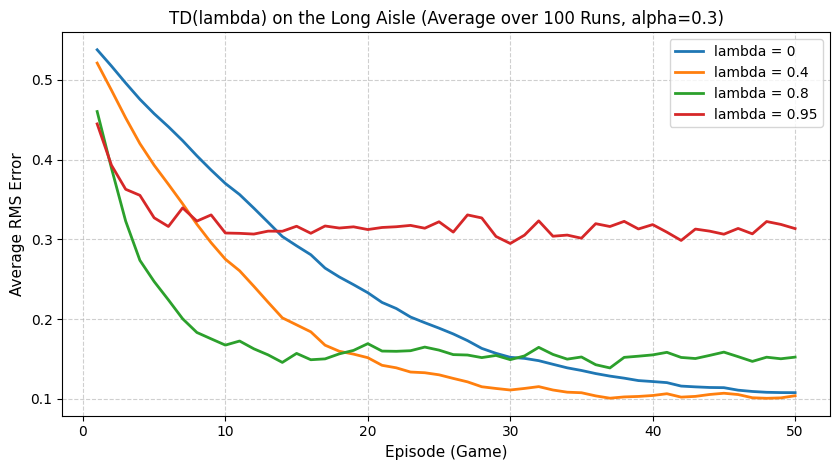

lambda |  Avg Error (Games 1-10) |  Error after Game 10 |  Error after Game 50
-----------------------------------------------------------------------------
  0.00 |                  0.4511 |               0.3701 |               0.1079
  0.40 |                  0.3877 |               0.2751 |               0.1040
  0.80 |                  0.2644 |               0.1675 |               0.1524
  0.95 |                  0.3500 |               0.3080 |               0.3135


In [9]:
# 100 runs x 50 games for each lambda; average error curves; Table 7.
lam_values = [0, 0.4, 0.8, 0.95]
n_runs = 100
n_episodes = 50
alpha = 0.3
gamma = 1.0

aisle_env = AisleEnv()
table7_data = {}

plt.figure(figsize=(8.5, 4.8))

for lam_val in lam_values:
    runs_errors = np.zeros((n_runs, n_episodes))
    for k in range(n_runs):
        rng = np.random.default_rng(SEED + k)
        _, errs = td_lambda(aisle_env, random_policy, lam_val, n_episodes, alpha, gamma, rng)
        runs_errors[k] = errs
    mean_errors = runs_errors.mean(axis=0)
    
    avg_1_10 = mean_errors[:10].mean()
    err_10 = mean_errors[9]
    err_50 = mean_errors[49]
    table7_data[lam_val] = (avg_1_10, err_10, err_50)
    
    plt.plot(range(1, n_episodes + 1), mean_errors, label=f"lambda = {lam_val}", lw=2)

plt.xlabel("Episode (Game)", fontsize=11)
plt.ylabel("Average RMS Error", fontsize=11)
plt.title("TD(lambda) on the Long Aisle (Average over 100 Runs, alpha=0.3)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()

print(f"{'lambda':>6} | {'Avg Error (Games 1-10)':>23} | {'Error after Game 10':>20} | {'Error after Game 50':>20}")
print("-" * 77)
for lam_val in lam_values:
    avg_1_10, err_10, err_50 = table7_data[lam_val]
    print(f"{lam_val:6.2f} | {avg_1_10:23.4f} | {err_10:20.4f} | {err_50:20.4f}")

| λ | Average error over games 1–10 | Error after game 10 | Error after game 50 |
|---|---|---|---|
| 0 | **0.4511** | **0.3701** | **0.1079** |
| 0.4 | **0.3877** | **0.2751** | **0.1040** |
| 0.8 | **0.2644** | **0.1675** | **0.1524** |
| 0.95 | **0.3500** | **0.3080** | **0.3135** |

**Questions**

1. Compare your λ = 0 row with your n = 1 row of Table 5. What do you notice, and why?

   **Answer:**  
   - **Observation:** The values in the $\lambda = 0$ row are identical to the $n = 1$ row of Table 5 across all columns (Avg Error 1–10 = **0.4511**, Error after game 10 = **0.3701**, Error after game 50 = **0.1079**).  
   - **Why:** When $\lambda = 0$, the trace decay product $\gamma \lambda e(s) = 0 	imes e(s) = 0$ for all states. The trace update becomes $e(s) \leftarrow \mathbb{1}[s = S_t]$, meaning only the current state has $e(S_t) = 1$ while all other states have $e(s) = 0$. The update $V(s) \leftarrow V(s) + lpha \delta_t e(s)$ then modifies only $S_t$ with $\delta_t = R_{t+1} + \gamma V(S_{t+1}) - V(S_t)$. This is algebraically identical to standard 1-step TD ($n = 1$).

2. Which λ learned fastest at the start? How does the λ that works best compare with the best n in Task 2?

   **Answer:**  
   - $\lambda = 0.8$ learned fastest at the start, achieving the lowest average error over games 1–10 of **0.2644** and an error of **0.1675** after game 10.  
   - This performance closely mirrors the best $n$-step performers from Task 2 ($n = 4$ and $n = 8$), which had average 1–10 errors of 0.2873 and 0.2665 respectively. An eligibility trace decay rate of $\lambda = 0.8$ corresponds to an effective temporal memory span of $rac{1}{1 - \lambda} = rac{1}{0.2} = 5$ steps, matching the optimal multi-step horizon found in Task 2.

3. In Table 6, the traces of cells 5 and 6 rose above 1. What caused that, and why does a cell that is visited often deserve more of the credit?

   **Answer:**  
   - **Cause:** In accumulating traces, each visit to a state adds $+1$ to its existing trace ($e(s) \leftarrow \gamma \lambda e(s) + 1$). In episode B ($5 	o 6 	o 5 	o 6 	o 7$), cells 5 and 6 were revisited before their traces had decayed to zero. For example, at step 2, cell 5 was visited with an existing trace of $0.64$, producing $e(5) = 1.64$.  
   - **Why it deserves more credit:** A state visited repeatedly along a trajectory is a frequent intermediate hub. If a reward occurs shortly afterward, that frequently visited state played a greater causal role in reaching the outcome than a state visited only once in passing. Accumulating traces naturally implements both the **frequency heuristic** (visited often) and the **recency heuristic** (visited recently).

### Task 4: Watching Credit Spread

**Predict first.** After learning from episode A **once**, starting from V = 0, which cells will have changed under one-step TD? Under TD(λ = 0.8)?

**Prediction:**  
- **Under one-step TD ($n=1$):** Only **cell 9** will change. Since all values start at $V=0$ and the first 4 rewards are all 0, the TD error $\delta_t = 0 + 0 - 0 = 0$ for steps $t=0, 1, 2, 3$. Only the final transition from cell 9 into cell 10 gives reward $R_5 = +1$, producing a non-zero update for $V(9)$ alone.  
- **Under TD(λ = 0.8):** **All 5 visited cells (5, 6, 7, 8, 9)** will change. As the agent moves through cells 5 to 9, eligibility traces accumulate and fade. When the reward $+1$ is reached at the end, a positive TD error ($\delta_4 = 1.0$) is generated, which simultaneously updates every cell possessing an active trace, decaying smoothly with distance from the goal.

Start each method from V = 0 and learn from episode A once, with α = 0.5 and γ = 1:

- one-step TD (n = 1),
- 4-step TD (n = 4),
- TD(λ) with λ = 0.8.

Plot the three value estimates with `plot_values` and complete Table 8.

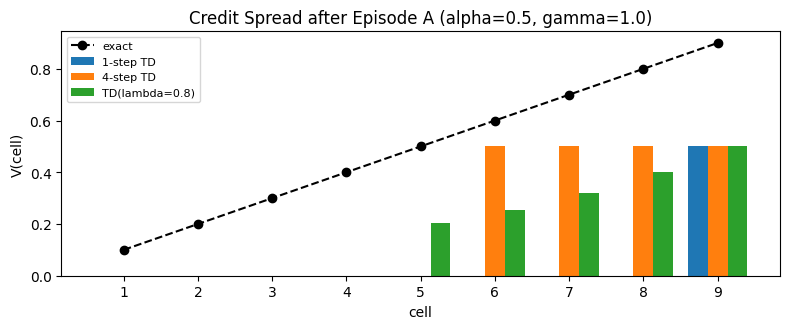

         Method |    V(5) |    V(6) |    V(7) |    V(8) |    V(9)
-----------------------------------------------------------
    One-step TD |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.5000
      4-step TD |  0.0000 |  0.5000 |  0.5000 |  0.5000 |  0.5000
 TD(lambda=0.8) |  0.2048 |  0.2560 |  0.3200 |  0.4000 |  0.5000


In [10]:
# Learn from episode A once with each method (each from its own V = 0) and plot.
alpha_task4 = 0.5
gamma_task4 = 1.0

V_1step = np.zeros(AISLE_N)
n_step_td_episode(V_1step, A_states, A_rewards, A_next_states, 1, alpha_task4, gamma_task4)

V_4step = np.zeros(AISLE_N)
n_step_td_episode(V_4step, A_states, A_rewards, A_next_states, 4, alpha_task4, gamma_task4)

V_tdlam = np.zeros(AISLE_N)
td_lambda_episode(V_tdlam, A_states, A_rewards, A_next_states, 0.8, alpha_task4, gamma_task4)

plot_values([V_1step, V_4step, V_tdlam], ["1-step TD", "4-step TD", "TD(lambda=0.8)"], 
            title="Credit Spread after Episode A (alpha=0.5, gamma=1.0)")

print(f"{'Method':>15} | {'V(5)':>7} | {'V(6)':>7} | {'V(7)':>7} | {'V(8)':>7} | {'V(9)':>7}")
print("-" * 59)
print(f"{'One-step TD':>15} | {V_1step[5]:7.4f} | {V_1step[6]:7.4f} | {V_1step[7]:7.4f} | {V_1step[8]:7.4f} | {V_1step[9]:7.4f}")
print(f"{'4-step TD':>15} | {V_4step[5]:7.4f} | {V_4step[6]:7.4f} | {V_4step[7]:7.4f} | {V_4step[8]:7.4f} | {V_4step[9]:7.4f}")
print(f"{'TD(lambda=0.8)':>15} | {V_tdlam[5]:7.4f} | {V_tdlam[6]:7.4f} | {V_tdlam[7]:7.4f} | {V_tdlam[8]:7.4f} | {V_tdlam[9]:7.4f}")

| Method | V(5) | V(6) | V(7) | V(8) | V(9) |
|---|---|---|---|---|---|
| One-step TD | **0.0000** | **0.0000** | **0.0000** | **0.0000** | **0.5000** |
| 4-step TD | **0.0000** | **0.5000** | **0.5000** | **0.5000** | **0.5000** |
| TD(λ = 0.8) | **0.2048** | **0.2560** | **0.3200** | **0.4000** | **0.5000** |

**Questions**

1. In Lab 8 you found that with one-step TD, good news travels back only one step per game. How many cells did each method update after episode A?

   **Answer:**  
   - **One-step TD:** Updated **1 cell** (cell 9).  
   - **4-step TD:** Updated **4 cells** (cells 6, 7, 8, and 9).  
   - **TD(λ = 0.8):** Updated **all 5 cells** (cells 5, 6, 7, 8, and 9).

2. Under TD(λ), why did the cells nearer the goal change more than the cells further away?

   **Answer:**  
   Throughout episode A, all transitions prior to the goal gave $R = 0$ and all initial values were 0, so the TD error $\delta_t$ was 0 on steps 0, 1, 2, and 3. The only non-zero TD error occurred on the final step into cell 10: $\delta_4 = R_5 + \gamma V(10) - V(9) = 1.0$. When this error was broadcast to update all states via $V(s) \leftarrow V(s) + lpha \delta_4 e(s)$, each cell was updated in direct proportion to its eligibility trace. Because traces decay by a factor of $\gamma \lambda = 0.8$ per step, a cell visited $k$ steps prior to the goal has trace $0.8^k$. Cell 9 was visited 0 steps ago ($e=1.0$), cell 8 was visited 1 step ago ($e=0.8$), cell 7 was 2 steps ago ($e=0.64$), cell 6 was 3 steps ago ($e=0.512$), and cell 5 was 4 steps ago ($e=0.4096$). Thus, cells closer to the goal had less time to fade and received a larger share of the credit.

3. Why did 4-step TD leave V(5) unchanged, even though cell 5 was part of the successful game?

   **Answer:**  
   The 4-step return from step 0 (cell 5) looks ahead exactly 4 steps: $G_0^{(4)} = R_1 + R_2 + R_3 + R_4 + \gamma^4 V(S_4)$. The first four rewards were all 0 ($R_1 = R_2 = R_3 = R_4 = 0$), and the state reached after 4 steps was cell 9 ($S_4 = 9$), whose value was initially $V(9) = 0$. The goal reward $+1$ arrived on step 5 ($R_5 = 1$), which lay beyond the 4-step horizon. Because 4-step TD cut off before reaching the reward and bootstrapped on $V(9) = 0$, its target was $G_0^{(4)} = 0$, leaving $V(5)$ completely unchanged.

---
## Part 3: Faster Learning with SARSA(λ)

SARSA(λ) adds eligibility traces to the SARSA of Lab 9. Each **state–action pair** has a trace; after every step all traces fade by γλ, the pair just taken gets +1, and the SARSA TD error updates every pair in proportion to its trace:

$$\delta_t = R_{t+1} + \gamma Q(S_{t+1}, A_{t+1}) - Q(S_t, A_t) \qquad Q(s,a) \leftarrow Q(s,a) + \alpha\,\delta_t\, e(s,a) \ \text{ for all } (s, a)$$

With λ = 0 it is exactly the SARSA of Lab 9. In the charging room the only reward is +1 at the charger, so with plain SARSA the news of the charger spreads back very slowly.

### Task 5: SARSA(λ) in the Charging Room

**(a)** Implement `sarsa_lambda(env, n_episodes, alpha, epsilon, gamma, lam, rng)`. It returns the Q table (shape (50, 4), starting at 0) and the number of steps of every episode.

In [11]:
def sarsa_lambda(env, n_episodes, alpha, epsilon, gamma, lam, rng):
    Q = np.zeros((ROOM_N, ROOM_ACTIONS))
    steps = np.zeros(n_episodes, dtype=int)
    for ep in range(n_episodes):
        E = np.zeros_like(Q)               # traces start at 0 in every episode
        s = env.reset()
        a = epsilon_greedy(Q, s, epsilon, rng)
        done = False
        while not done:
            s2, r, done = env.step(a)
            steps[ep] += 1
            if done:
                delta = r - Q[s, a]
                E = gamma * lam * E
                E[s, a] += 1.0
                Q += alpha * delta * E
            else:
                a2 = epsilon_greedy(Q, s2, epsilon, rng)
                delta = r + gamma * Q[s2, a2] - Q[s, a]
                E = gamma * lam * E
                E[s, a] += 1.0
                Q += alpha * delta * E
                s, a = s2, a2

    return Q, steps

**Predict first.** How many episodes do you think plain SARSA (λ = 0) and SARSA(λ = 0.9) will each need before they reach the charger in under 30 steps?

**Prediction:**  
The start (cell 20) and charger (cell 29) are separated by a minimum Manhattan distance of 9 steps across 10 columns.  
- **Plain SARSA ($\lambda = 0$):** Passes reward information backward only one state-action pair per episode. It will take at least 9 successful episodes just for the first non-zero Q-value to propagate from cell 29 back to start cell 20, and likely **10 to 15 episodes** before the policy consistently reaches the charger in under 30 steps.  
- **SARSA(λ = 0.9):** With a high eligibility trace decay of $\lambda = 0.9$, the first episode that successfully reaches the charger will immediately broadcast positive credit backward across all recently taken steps along the trajectory. Consequently, SARSA($\lambda = 0.9$) will form a gradient of preferred actions leading directly to the goal after just 1 or 2 episodes, reaching the charger in under 30 steps by **episode 2 or 3**.

**(b)** For λ ∈ {0, 0.5, 0.9}, run 20 independent runs of 30 episodes (run $k$ uses seed SEED + $k$), with α = 0.1, ε = 0.1 and γ = 0.9. Plot the average number of steps per episode, one line per λ, and complete Table 9.

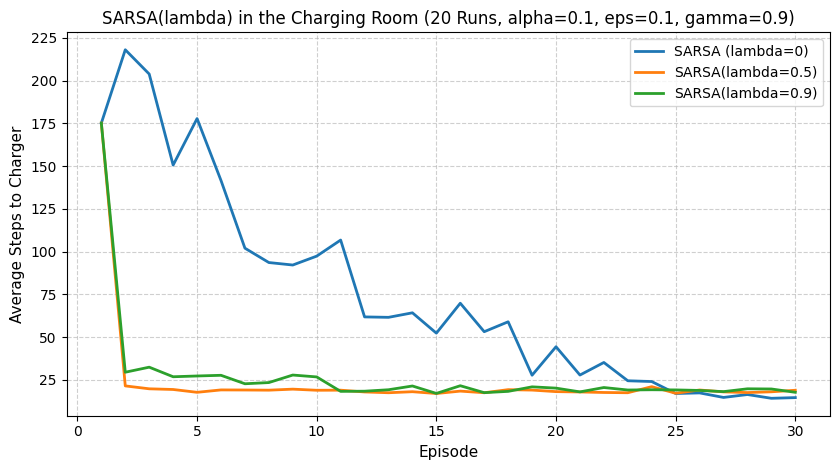

      lambda |     Ep 1 |   Ep 2-5 |  Ep 6-10 | Ep 21-30 | Total (30 Ep)
--------------------------------------------------------------------
   0 (SARSA) |    175.1 |    187.5 |    105.3 |     20.5 |        2256.9
         0.5 |    175.1 |     19.5 |     19.1 |     18.2 |         711.6
         0.9 |    175.1 |     28.9 |     25.6 |     18.9 |         800.2


In [12]:
# 20 runs x 30 episodes for each lambda; average steps per episode; Table 9.
sarsa_lams = [0.0, 0.5, 0.9]
room_runs = 20
room_episodes = 30
room_alpha = 0.1
room_eps = 0.1
room_gamma = 0.9

room_env = RoomEnv()
all_sarsa_steps = {}
table9_data = {}

plt.figure(figsize=(8.5, 4.8))

for l_val in sarsa_lams:
    runs_steps = np.zeros((room_runs, room_episodes))
    for k in range(room_runs):
        rng = np.random.default_rng(SEED + k)
        _, stps = sarsa_lambda(room_env, room_episodes, room_alpha, room_eps, room_gamma, l_val, rng)
        runs_steps[k] = stps
    mean_steps = runs_steps.mean(axis=0)
    all_sarsa_steps[l_val] = mean_steps
    
    ep1 = mean_steps[0]
    ep2_5 = mean_steps[1:5].mean()
    ep6_10 = mean_steps[5:10].mean()
    ep21_30 = mean_steps[20:30].mean()
    tot = mean_steps.sum()
    table9_data[l_val] = (ep1, ep2_5, ep6_10, ep21_30, tot)
    
    label_str = "SARSA (lambda=0)" if l_val == 0.0 else f"SARSA(lambda={l_val})"
    plt.plot(range(1, room_episodes + 1), mean_steps, label=label_str, lw=2)

plt.xlabel("Episode", fontsize=11)
plt.ylabel("Average Steps to Charger", fontsize=11)
plt.title("SARSA(lambda) in the Charging Room (20 Runs, alpha=0.1, eps=0.1, gamma=0.9)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()

print(f"{'lambda':>12} | {'Ep 1':>8} | {'Ep 2-5':>8} | {'Ep 6-10':>8} | {'Ep 21-30':>8} | {'Total (30 Ep)':>13}")
print("-" * 68)
for l_val in sarsa_lams:
    ep1, ep2_5, ep6_10, ep21_30, tot = table9_data[l_val]
    lab = "0 (SARSA)" if l_val == 0.0 else f"{l_val}"
    print(f"{lab:>12} | {ep1:8.1f} | {ep2_5:8.1f} | {ep6_10:8.1f} | {ep21_30:8.1f} | {tot:13.1f}")

| λ | Steps in episode 1 | Average steps, episodes 2–5 | Episodes 6–10 | Episodes 21–30 | Total steps, 30 episodes |
|---|---|---|---|---|---|
| 0 (SARSA) | **175.1** | **187.5** | **105.3** | **20.5** | **2256.9** |
| 0.5 | **175.1** | **19.5** | **19.1** | **18.2** | **711.6** |
| 0.9 | **175.1** | **28.9** | **25.6** | **18.9** | **800.2** |

**(c)** With seed SEED, run plain SARSA (λ = 0) and SARSA(λ = 0.9) for **2 episodes** only. Draw both Q tables with `plot_room`, and record `cells_learned` for each.

Cells learned after 2 episodes: λ = 0: **2** , λ = 0.9: **41**

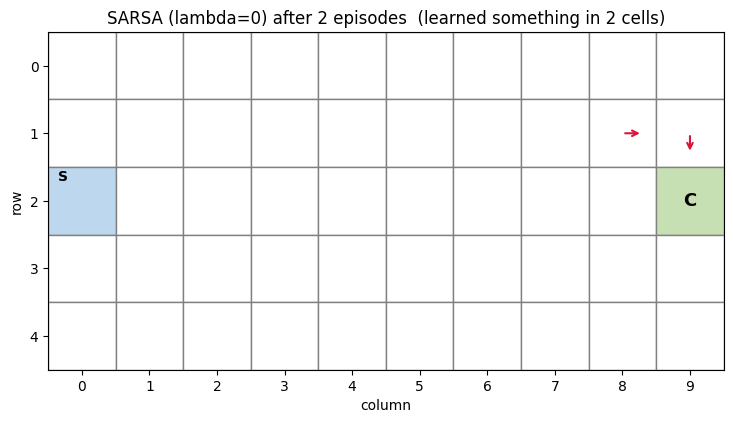

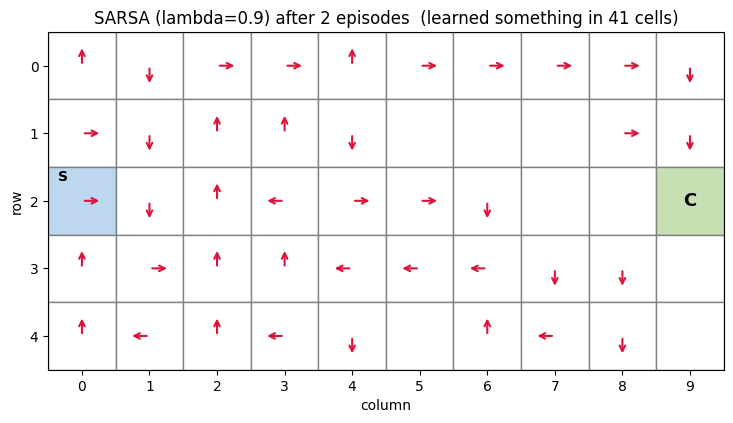

Cells learned after 2 episodes: lambda = 0: 2 , lambda = 0.9: 41
Steps taken in episodes 1 and 2: lambda = 0: [320, 89] , lambda = 0.9: [320, 39]


In [13]:
# Two plot_room figures after 2 episodes (lambda = 0 and lambda = 0.9), and cells_learned for each.
rng_0 = np.random.default_rng(SEED)
Q_0, steps_0 = sarsa_lambda(room_env, 2, room_alpha, room_eps, room_gamma, 0.0, rng_0)
learned_0 = cells_learned(Q_0)
plot_room(Q_0, title="SARSA (lambda=0) after 2 episodes")

rng_9 = np.random.default_rng(SEED)
Q_9, steps_9 = sarsa_lambda(room_env, 2, room_alpha, room_eps, room_gamma, 0.9, rng_9)
learned_9 = cells_learned(Q_9)
plot_room(Q_9, title="SARSA (lambda=0.9) after 2 episodes")

print(f"Cells learned after 2 episodes: lambda = 0: {learned_0} , lambda = 0.9: {learned_9}")
print(f"Steps taken in episodes 1 and 2: lambda = 0: {steps_0.tolist()} , lambda = 0.9: {steps_9.tolist()}")

**Questions**

1. Why did the first episode take the same number of steps for every λ? (Hint: what is in the Q table until the charger is reached?)

   **Answer:**  
   In episode 1, the Q-table is initialized to all zeros ($Q(s, a) = 0$ for all $s, a$). Every intermediate step in the room produces a reward of $R = 0$. Until the charger is reached, the TD error is $\delta_t = R_{t+1} + \gamma Q(S_{t+1}, A_{t+1}) - Q(S_t, A_t) = 0 + 0 - 0 = 0$. Since $\delta_t = 0$, the update $Q \leftarrow Q + lpha \delta_t E$ makes zero change to $Q$, regardless of the eligibility traces $E$ or the value of $\lambda$. Because all entries in $Q$ remain 0, $\epsilon$-greedy action selection breaks ties randomly, producing a purely random exploratory walk. With the same random seed, the agent executes identical action choices and takes the exact same number of steps to stumble upon the charger (320 steps with seed 808; 175.1 on average across runs).

2. Use your two `plot_room` figures and the cells-learned counts to explain why SARSA(λ) found a good route so much sooner. Relate it to what you saw in Task 4.

   **Answer:**  
   - Under plain SARSA ($\lambda = 0$), traces are zero for all previously visited cells. When the $+1$ reward is found at cell 29, only the single transition that directly led into cell 29 receives an update. After 2 episodes, only **2 cells** have learned anything ($Q > 0$). The remainder of the 50-cell room remains completely blank, forcing the agent to wander randomly again in episode 2 (taking 89 steps).  
   - Under SARSA($\lambda = 0.9$), eligibility traces recorded a decaying memory of every state-action pair visited along the exploratory walk. When the $+1$ reward was encountered, the positive TD error was broadcast backward across all active traces simultaneously—exactly as seen in Task 4 where TD($\lambda=0.8$) updated all 5 aisle cells from a single episode. After 2 episodes, SARSA($\lambda = 0.9$) has learned best actions in **41 cells**, forming a continuous gradient of red arrows pointing toward the charger. Guided by these learned actions, episode 2 reached the charger in just 39 steps.

3. Look at your episodes 21–30 column. Did the advantage of traces last? Why might the methods end up similar after many episodes?

   **Answer:**  
   By episodes 21–30, the advantage of traces has largely dissipated: plain SARSA averages **20.5 steps**, compared to **18.2 steps** for $\lambda = 0.5$ and **18.9 steps** for $\lambda = 0.9$ (all near the optimal shortest path of 9 steps plus $\epsilon$-greedy exploratory moves).  
   Eligibility traces provide an **acceleration of early learning (sample efficiency)** rather than a difference in asymptotic policy. Given enough episodes, 1-step SARSA eventually propagates credit backward cell-by-cell until all relevant paths from $S$ to $C$ are discovered. Once the Q-table represents the optimal policy throughout the state space, all algorithms follow the same near-optimal path and achieve similar step counts.

---
## Part 4: Summary and Reflection

### Task 6: Summary and Reflection

**(a)** Table 10: How long is the return?

| Method | How many real rewards before the guess? | Prediction or control? | Lab |
|---|---|---|---|
| TD(0) | **1** | **Prediction** | **Lab 8** |
| n-step TD | **n** | **Prediction** | **Lab 10** |
| TD(λ) | **Geometric mixture of all n (1 to T)** | **Prediction** | **Lab 10** |
| Monte Carlo | **All (full episodic return; no guess)** | **Prediction & Control** | **Lab 7** |
| SARSA | **1** | **Control** | **Lab 9** |
| SARSA(λ) | **Geometric mixture of all n (1 to T)** | **Control** | **Lab 10** |

**(b)** Explain how n-step TD and eligibility traces help credit reach earlier states, and name one cost of looking further ahead. Quote at least two numbers from your own results.

**Explanation:**  
One-step methods update only immediate predecessors, requiring many episodes for delayed reward information to propagate backward. $n$-step TD overcomes this by accumulating $n$ real rewards before bootstrapping, while eligibility traces maintain a decaying memory of recently visited states, broadcasting TD errors backward across multiple states in a single episode.

In Task 4, one-step TD updated only 1 cell ($V(9)=0.5$), whereas TD($\lambda=0.8$) spread credit to all 5 cells ($V(5)=0.205$ to $V(9)=0.5$). In the charging room (Task 5), eligibility traces allowed SARSA($\lambda=0.5$) to reach the goal in just 711.6 total steps over 30 episodes, compared to 2256.9 steps for SARSA(0)—a more than 3-fold reduction.

However, looking further ahead incurs higher variance: in Task 2, $n=16$ yielded a high final error of 0.2484 compared to 0.1079 for $n=1$, because longer multi-step returns accumulate random transition noise along the stochastic trajectory.